In [1]:
# WEEK 2: DATA COLLECTION, CLEANING & PREPROCESSING
# Food Delivery Logistics Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
# Load the publicly available logistics dataset

url = "/content/zomato_delivery.csv.csv"
df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (38964, 22)


In [6]:
# Create a backup of the original dataset
df_raw = df.copy()

print("Original dataset backup created successfully!")
print("Original shape:", df_raw.shape)
print("Working dataset shape:", df.shape)

Original dataset backup created successfully!
Original shape: (38964, 22)
Working dataset shape: (38964, 22)


In [7]:
# Display the first 5 rows
print("First 5 rows of the dataset:")
display(df.head())

First 5 rows of the dataset:


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,...,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min),distance_km,delivery_speed
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,...,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46,10.280582,Slow
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,...,High,1,Meal,motorcycle,1.0,No,Metropolitian,23,6.242319,Average
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,...,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21,13.787860,Average
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,...,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20,2.930258,Average
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,...,Jam,1,Snack,scooter,1.0,No,Metropolitian,41,19.396618,Slow


In [8]:
# Check dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38964 entries, 0 to 38963
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           38964 non-null  object 
 1   Delivery_person_ID           38964 non-null  object 
 2   Delivery_person_Age          37945 non-null  float64
 3   Delivery_person_Ratings      37909 non-null  float64
 4   Restaurant_latitude          38964 non-null  float64
 5   Restaurant_longitude         38964 non-null  float64
 6   Delivery_location_latitude   38964 non-null  float64
 7   Delivery_location_longitude  38964 non-null  float64
 8   Order_Date                   38964 non-null  object 
 9   Time_Orderd                  38129 non-null  object 
 10  Time_Order_picked            38964 non-null  object 
 11  Weather_conditions           38964 non-null  object 
 12  Road_traffic_density         38964 non-null  object 
 13  Vehicle_conditio

In [9]:
# Count missing values in each column

missing_count = df.isnull().sum()

print("Missing values in each column:")
display(missing_count[missing_count > 0])

Missing values in each column:


,0
Delivery_person_Age,1019
Delivery_person_Ratings,1055
Time_Orderd,835


In [10]:
# Calculate missing value percentage

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": missing_percentage
})

missing_summary = missing_summary[missing_summary["Missing Count"] > 0]

display(missing_summary)

,Missing Count,Missing Percentage
Delivery_person_Age,1019,2.615235
Delivery_person_Ratings,1055,2.707628
Time_Orderd,835,2.143004


In [11]:
# Check for duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [12]:
# Calculate percentage of duplicate rows

duplicate_percentage = (duplicate_count / len(df)) * 100

print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

Duplicate percentage: 0.00%


In [13]:
# Check data types of all columns

print("Data types of each column:")
display(df.dtypes)

Data types of each column:


,0
ID,object
Delivery_person_ID,object
Delivery_person_Age,float64
Delivery_person_Ratings,float64
Restaurant_latitude,float64
Restaurant_longitude,float64
Delivery_location_latitude,float64
Delivery_location_longitude,float64
Order_Date,object
Time_Orderd,object


In [14]:
# Display numerical columns

print("Numerical columns:")
display(df.select_dtypes(include=np.number).columns.tolist())

Numerical columns:


['Delivery_person_Age',
 'Delivery_person_Ratings',
 'Restaurant_latitude',
 'Restaurant_longitude',
 'Delivery_location_latitude',
 'Delivery_location_longitude',
 'Vehicle_condition',
 'multiple_deliveries',
 'Time_taken (min)',
 'distance_km']

In [15]:
# Display categorical/text columns

print("Categorical/Text columns:")
display(df.select_dtypes(include="object").columns.tolist())

Categorical/Text columns:


['ID',
 'Delivery_person_ID',
 'Order_Date',
 'Time_Orderd',
 'Time_Order_picked',
 'Weather_conditions',
 'Road_traffic_density',
 'Type_of_order',
 'Type_of_vehicle',
 'Festival',
 'City',
 'delivery_speed']

In [16]:
# Statistical summary of numerical columns

display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Delivery_person_Age,37945.0,29.607089,5.763202,20.000000,25.000000,30.000000,35.000000,39.000000
Delivery_person_Ratings,37909.0,4.631879,0.317006,2.500000,4.500000,4.700000,4.900000,5.000000
Restaurant_latitude,38964.0,18.915583,5.460635,9.957144,12.986047,19.065838,22.751234,30.914057
Restaurant_longitude,38964.0,76.914536,3.498179,72.768726,73.897902,76.618203,78.368855,88.433452
Delivery_location_latitude,38964.0,18.979545,5.462504,9.967144,13.066047,19.124049,22.820072,31.054057
Delivery_location_longitude,38964.0,76.978498,3.498357,72.778726,73.938972,76.663067,78.405467,88.563452
Vehicle_condition,38964.0,0.995534,0.817312,0.000000,0.000000,1.000000,2.000000,2.000000
multiple_deliveries,38964.0,0.749589,0.572172,0.000000,0.000000,1.000000,1.000000,3.000000
Time_taken (min),38964.0,26.581511,9.339546,10.000000,19.000000,26.000000,33.000000,54.000000
distance_km,38964.0,9.765092,5.605705,1.465067,4.658009,9.219906,13.681590,20.969489


In [17]:
# Check age range

print("Minimum age:", df["Delivery_person_Age"].min())
print("Maximum age:", df["Delivery_person_Age"].max())

Minimum age: 20.0
Maximum age: 39.0


In [18]:
# Check rating range

print("Minimum rating:", df["Delivery_person_Ratings"].min())
print("Maximum rating:", df["Delivery_person_Ratings"].max())

Minimum rating: 2.5
Maximum rating: 5.0


In [19]:
# Check delivery time range

print("Minimum delivery time:", df["Time_taken (min)"].min())
print("Maximum delivery time:", df["Time_taken (min)"].max())

Minimum delivery time: 10
Maximum delivery time: 54


In [20]:
#CHECK WEATHER CONDITIONS

print("Weather conditions:")
print(df["Weather_conditions"].value_counts(dropna=False))

Weather conditions:
Weather_conditions
Fog           6660
Stormy        6572
Cloudy        6563
Sandstorms    6489
Windy         6436
Sunny         6244
Name: count, dtype: int64


In [21]:
#CHECK ROAD TRAFFIC DENSITY

print("Road traffic density:")
print(df["Road_traffic_density"].value_counts(dropna=False))

Road traffic density:
Road_traffic_density
Low       13139
Jam       12414
Medium     9556
High       3855
Name: count, dtype: int64


In [22]:
#CHECK FESTIVAL VALUES

print("Festival values:")
print(df["Festival"].value_counts(dropna=False))

Festival values:
Festival
No     38180
Yes      784
Name: count, dtype: int64


In [23]:
#CHECK CITY CATEGORIES

print("City categories:")
print(df["City"].value_counts(dropna=False))

City categories:
City
Metropolitian    30036
Urban             8782
Semi-Urban         146
Name: count, dtype: int64


In [24]:
#CHECK VEHICLE CONDITION

print("Vehicle condition:")
print(df["Vehicle_condition"].value_counts(dropna=False))

Vehicle condition:
Vehicle_condition
0    13101
1    12936
2    12927
Name: count, dtype: int64


In [25]:
#REMOVE DUPLICATE ROWS

# Count duplicates before removal
duplicates_before = df.duplicated().sum()

print("Duplicate rows before cleaning:", duplicates_before)

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

# Check shape after removal
print("Dataset shape after removing duplicates:", df.shape)
print("Duplicate rows after cleaning:", df.duplicated().sum())

Duplicate rows before cleaning: 0
Dataset shape after removing duplicates: (38964, 22)
Duplicate rows after cleaning: 0


In [26]:
# VALIDATE DELIVERY PERSON AGE

# Identify potentially invalid age values
invalid_age = df[
    (df["Delivery_person_Age"] < 18) |
    (df["Delivery_person_Age"] > 60)
]

print("Potentially invalid age records:", len(invalid_age))

# Display the unusual age values
display(invalid_age[["Delivery_person_Age"]].drop_duplicates())

Potentially invalid age records: 0


,Delivery_person_Age


In [27]:
#  VALIDATE DELIVERY PERSON RATINGS

# Identify ratings outside the expected 1–5 range
invalid_ratings = df[
    (df["Delivery_person_Ratings"] < 1) |
    (df["Delivery_person_Ratings"] > 5)
]

print("Invalid rating records:", len(invalid_ratings))

# Display unusual rating values
display(invalid_ratings[["Delivery_person_Ratings"]].drop_duplicates())

Invalid rating records: 0


,Delivery_person_Ratings


In [28]:
# VALIDATE DELIVERY TIME

invalid_time = df[
    df["Time_taken (min)"] <= 0
]

print("Invalid delivery-time records:", len(invalid_time))

# Display invalid values
display(invalid_time[["Time_taken (min)"]].drop_duplicates())

Invalid delivery-time records: 0


,Time_taken (min)


In [29]:
# VALIDATE DELIVERY DISTANCE

invalid_distance = df[
    df["distance_km"] <= 0
]

print("Invalid distance records:", len(invalid_distance))

# Display invalid values
display(invalid_distance[["distance_km"]].drop_duplicates())

Invalid distance records: 0


,distance_km


In [30]:
# MISSING VALUES BEFORE TREATMENT

missing_before = df.isnull().sum()

print("Missing values before treatment:")
display(missing_before[missing_before > 0])

Missing values before treatment:


,0
Delivery_person_Age,1019
Delivery_person_Ratings,1055
Time_Orderd,835


In [31]:
# IMPUTE MISSING DELIVERY PERSON AGE

age_median = df["Delivery_person_Age"].median()

df["Delivery_person_Age"] = df["Delivery_person_Age"].fillna(age_median)

print("Median age used for imputation:", age_median)
print(
    "Missing age values after treatment:",
    df["Delivery_person_Age"].isnull().sum()
)

Median age used for imputation: 30.0
Missing age values after treatment: 0


In [32]:
# IMPUTE MISSING DELIVERY RATINGS

rating_median = df["Delivery_person_Ratings"].median()

df["Delivery_person_Ratings"] = df["Delivery_person_Ratings"].fillna(
    rating_median
)

print("Median rating used for imputation:", rating_median)
print(
    "Missing rating values after treatment:",
    df["Delivery_person_Ratings"].isnull().sum()
)

Median rating used for imputation: 4.7
Missing rating values after treatment: 0


In [33]:
# IMPUTE MISSING WEATHER CONDITIONS

weather_mode = df["Weather_conditions"].mode()[0]

df["Weather_conditions"] = df["Weather_conditions"].fillna(
    weather_mode
)

print("Mode used for weather:", weather_mode)
print(
    "Missing weather values after treatment:",
    df["Weather_conditions"].isnull().sum()
)

Mode used for weather: Fog
Missing weather values after treatment: 0


In [34]:
# IMPUTE MISSING ROAD TRAFFIC DENSITY
traffic_mode = df["Road_traffic_density"].mode()[0]

df["Road_traffic_density"] = df["Road_traffic_density"].fillna(
    traffic_mode
)

print("Mode used for traffic density:", traffic_mode)
print(
    "Missing traffic values after treatment:",
    df["Road_traffic_density"].isnull().sum()
)

Mode used for traffic density: Low
Missing traffic values after treatment: 0


In [35]:
# IMPUTE MISSING FESTIVAL VALUES
festival_mode = df["Festival"].mode()[0]

df["Festival"] = df["Festival"].fillna(
    festival_mode
)

print("Mode used for festival:", festival_mode)
print(
    "Missing festival values after treatment:",
    df["Festival"].isnull().sum()
)

Mode used for festival: No
Missing festival values after treatment: 0


In [36]:
# VERIFY MISSING VALUES AFTER TREATMENT
missing_after = df.isnull().sum()

print("Remaining missing values:")
display(missing_after[missing_after > 0])

Remaining missing values:


,0
Time_Orderd,835


In [38]:
# CONVERT TIME_ORDERD TO DATETIME FORMAT
df["Time_Orderd"] = pd.to_datetime(
    df["Time_Orderd"],
    format="%H:%M",
    errors="coerce"
)

print("Time_Orderd data type after conversion:")
print(df["Time_Orderd"].dtype)

print("\nMissing values after conversion:")
print(df["Time_Orderd"].isnull().sum())

Time_Orderd data type after conversion:
datetime64[ns]

Missing values after conversion:
4345


In [39]:
# EXTRACT ORDER HOUR
df["order_hour"] = df["Time_Orderd"].dt.hour

print("Sample of Time_Orderd and extracted order_hour:")
display(df[["Time_Orderd", "order_hour"]].head(10))

Sample of Time_Orderd and extracted order_hour:


,Time_Orderd,order_hour
0,1900-01-01 21:55:00,21.0
1,1900-01-01 14:55:00,14.0
2,1900-01-01 17:30:00,17.0
3,1900-01-01 09:20:00,9.0
4,1900-01-01 19:50:00,19.0
5,1900-01-01 20:25:00,20.0
6,1900-01-01 14:55:00,14.0
7,1900-01-01 20:30:00,20.0
8,1900-01-01 21:15:00,21.0
9,1900-01-01 20:20:00,20.0


In [40]:
# FINAL MISSING VALUE CHECK
remaining_missing = df.isnull().sum()

print("Remaining missing values:")
display(remaining_missing[remaining_missing > 0])

Remaining missing values:


,0
Time_Orderd,4345
order_hour,4345


In [42]:
# CHECK ORIGINAL TIME VALUES
# Check the original, untouched Time_Orderd column
print("Original Time_Orderd values:")

display(
    df_raw["Time_Orderd"].value_counts(dropna=False).head(30)
)


Original Time_Orderd values:


,count
Time_Orderd,
NaN,835
17:55,407
21:55,402
19:50,401
21:15,399
18:35,396
19:55,394
0.833333333,388
21:35,385


In [43]:
# CORRECT TIME_ORDERD CLEANING
# Restore the original Time_Orderd column
df["Time_Orderd"] = df_raw["Time_Orderd"].copy()

# Function to convert different time formats into a common time format
def convert_order_time(value):

    # Keep missing values as missing
    if pd.isna(value):
        return pd.NaT

    # Handle decimal fraction of a day
    if isinstance(value, (float, int)):
        total_minutes = round(float(value) * 24 * 60)

        hours = total_minutes // 60
        minutes = total_minutes % 60

        return pd.Timestamp(
            year=1900,
            month=1,
            day=1,
            hour=hours % 24,
            minute=minutes
        )

    # Handle normal time strings such as 21:55
    try:
        return pd.to_datetime(
            str(value),
            format="%H:%M",
            errors="coerce"
        )
    except:
        return pd.NaT


# Apply the conversion
df["Time_Orderd"] = df["Time_Orderd"].apply(convert_order_time)

print("Time_Orderd conversion completed!")
print("Data type:", df["Time_Orderd"].dtype)

print("\nMissing Time_Orderd values:")
print(df["Time_Orderd"].isnull().sum())

Time_Orderd conversion completed!
Data type: datetime64[ns]

Missing Time_Orderd values:
4345


In [47]:
#  FIND THE ORIGINAL CSV FILE
import os

print("CSV files available in /content:")

for file in os.listdir("/content"):
    if file.lower().endswith(".csv"):
        print(file)

CSV files available in /content:
zomato_delivery.csv.csv


In [48]:
# RELOAD ORIGINAL DATA
# Load the original CSV file
df_original = pd.read_csv("/content/zomato_delivery.csv.csv")

print("Original CSV loaded successfully!")
print("Original dataset shape:", df_original.shape)

print("\nOriginal Time_Orderd missing values:")
print(df_original["Time_Orderd"].isnull().sum())

print("\nSample of original Time_Orderd values:")
display(
    df_original["Time_Orderd"]
    .value_counts(dropna=False)
    .head(15)
)

Original CSV loaded successfully!
Original dataset shape: (38964, 22)

Original Time_Orderd missing values:
835

Sample of original Time_Orderd values:


,count
Time_Orderd,
NaN,835
17:55,407
21:55,402
19:50,401
21:15,399
18:35,396
19:55,394
0.833333333,388
21:35,385


In [49]:
# CORRECTLY CONVERT Time_Orderd
# Restore Time_Orderd from the original CSV
df["Time_Orderd"] = df_original["Time_Orderd"].copy()


# Function to convert all time formats
def convert_order_time(value):

    # Keep missing values as missing
    if pd.isna(value):
        return pd.NaT

    # Handle decimal fraction of a day
    try:
        numeric_value = float(value)

        # Values between 0 and 1 represent a fraction of a day
        if 0 <= numeric_value < 1:

            total_minutes = round(numeric_value * 24 * 60)

            hours = total_minutes // 60
            minutes = total_minutes % 60

            return pd.Timestamp(
                year=1900,
                month=1,
                day=1,
                hour=hours % 24,
                minute=minutes
            )

    except (ValueError, TypeError):
        pass


    # Handle normal time values such as 21:55
    return pd.to_datetime(
        str(value),
        format="%H:%M",
        errors="coerce"
    )


# Apply conversion
df["Time_Orderd"] = df["Time_Orderd"].apply(convert_order_time)


print("Time_Orderd conversion completed!")
print("Data type:", df["Time_Orderd"].dtype)

print("\nMissing Time_Orderd values after conversion:")
print(df["Time_Orderd"].isnull().sum())

Time_Orderd conversion completed!
Data type: datetime64[ns]

Missing Time_Orderd values after conversion:
1204


In [50]:
# FIND UNCONVERTED TIME VALUES
# Compare the original values with the successfully converted values
problem_values = df_original.loc[
    df["Time_Orderd"].isna() & df_original["Time_Orderd"].notna(),
    "Time_Orderd"
]

print("Number of non-missing original values that could not be converted:")
print(problem_values.shape[0])

print("\nUnconverted values and their frequencies:")
display(
    problem_values.value_counts().head(30)
)

Number of non-missing original values that could not be converted:
369

Unconverted values and their frequencies:


,count
Time_Orderd,
1,369


In [51]:
# HANDLE NUMERIC TIME VALUE 1
# Identify rows where the original value is exactly 1
mask_one = df_original["Time_Orderd"] == 1

# Convert numeric value 1 to midnight (00:00)
df.loc[mask_one, "Time_Orderd"] = pd.Timestamp(
    year=1900,
    month=1,
    day=1,
    hour=0,
    minute=0
)

print("Number of Time_Orderd values converted from 1:")
print(mask_one.sum())

print("\nMissing Time_Orderd values after correction:")
print(df["Time_Orderd"].isnull().sum())

Number of Time_Orderd values converted from 1:
0

Missing Time_Orderd values after correction:
1204


In [52]:
# FINAL TIME_ORDERD CLEANING
# Start again from the untouched original CSV column
original_time = df_original["Time_Orderd"]


# ------------------------------------------------------------
# Function to convert every time format
# ------------------------------------------------------------

def clean_time(value):

    # Keep genuinely missing values as missing
    if pd.isna(value):
        return pd.NaT

    # Convert value to string for consistent checking
    value_str = str(value).strip()


    # Handle missing-like text
    if value_str.lower() in ["nan", "none", ""]:
        return pd.NaT


    # Handle numeric values such as 0.833333333 and 1
    try:
        numeric_value = float(value_str)

        # Fraction of a day
        if 0 <= numeric_value <= 1:

            total_minutes = round(numeric_value * 24 * 60)

            # Keep time within a 24-hour day
            total_minutes = total_minutes % (24 * 60)

            hours = total_minutes // 60
            minutes = total_minutes % 60

            return pd.Timestamp(
                year=1900,
                month=1,
                day=1,
                hour=hours,
                minute=minutes
            )

    except (ValueError, TypeError):
        pass


    # Handle normal values such as 21:55
    return pd.to_datetime(
        value_str,
        format="%H:%M",
        errors="coerce"
    )


# Apply the cleaning
df["Time_Orderd"] = original_time.apply(clean_time)


# ------------------------------------------------------------
# Final verification
# ------------------------------------------------------------

print("Time_Orderd cleaning completed!")

print("\nData type:")
print(df["Time_Orderd"].dtype)

print("\nMissing Time_Orderd values:")
print(df["Time_Orderd"].isnull().sum())

print("\nSample of cleaned Time_Orderd:")
display(df[["Time_Orderd"]].head(15))

Time_Orderd cleaning completed!

Data type:
datetime64[ns]

Missing Time_Orderd values:
835

Sample of cleaned Time_Orderd:


,Time_Orderd
0,1900-01-01 21:55:00
1,1900-01-01 14:55:00
2,1900-01-01 17:30:00
3,1900-01-01 09:20:00
4,1900-01-01 19:50:00
5,1900-01-01 20:25:00
6,1900-01-01 14:55:00
7,1900-01-01 20:30:00
8,1900-01-01 21:15:00
9,1900-01-01 20:20:00


In [53]:
# EXTRACT ORDER HOUR
# Extract the hour from Time_Orderd
df["order_hour"] = df["Time_Orderd"].dt.hour

print("Order hour extraction completed!")

print("\nSample of Time_Orderd and order_hour:")
display(
    df[["Time_Orderd", "order_hour"]].head(15)
)

print("\nMissing order_hour values:")
print(df["order_hour"].isnull().sum())

Order hour extraction completed!

Sample of Time_Orderd and order_hour:


,Time_Orderd,order_hour
0,1900-01-01 21:55:00,21.0
1,1900-01-01 14:55:00,14.0
2,1900-01-01 17:30:00,17.0
3,1900-01-01 09:20:00,9.0
4,1900-01-01 19:50:00,19.0
5,1900-01-01 20:25:00,20.0
6,1900-01-01 14:55:00,14.0
7,1900-01-01 20:30:00,20.0
8,1900-01-01 21:15:00,21.0
9,1900-01-01 20:20:00,20.0



Missing order_hour values:
835


In [54]:
# FINAL MISSING VALUE CHECK
# Count missing values in the cleaned dataset
final_missing = df.isnull().sum()

print("Remaining missing values after Step 12:")

display(
    final_missing[final_missing > 0]
)

Remaining missing values after Step 12:


,0
Time_Orderd,835
order_hour,835


In [55]:
# SELECT VARIABLES FOR OUTLIER ANALYSIS
# Continuous numerical variables suitable for IQR analysis
outlier_columns = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Time_taken (min)",
    "distance_km",
    "delivery_speed"
]

print("Variables selected for outlier analysis:")

for column in outlier_columns:
    print("-", column)

Variables selected for outlier analysis:
- Delivery_person_Age
- Delivery_person_Ratings
- Time_taken (min)
- distance_km
- delivery_speed


In [57]:
# CHECK DATA TYPES OF OUTLIER VARIABLES

print("Data types of selected outlier variables:")

for column in outlier_columns:
    print(f"{column} --> {df[column].dtype}")

Data types of selected outlier variables:
Delivery_person_Age --> float64
Delivery_person_Ratings --> float64
Time_taken (min) --> int64
distance_km --> float64
delivery_speed --> object


In [58]:
# INSPECT DELIVERY SPEED VALUES
print("Sample delivery_speed values:")

display(
    df["delivery_speed"].head(20)
)

print("\nData type:")
print(df["delivery_speed"].dtype)

print("\nNumber of unique values:")
print(df["delivery_speed"].nunique())

print("\nSample unique values:")
display(
    df["delivery_speed"].dropna().unique()[:20]
)

Sample delivery_speed values:


,delivery_speed
0,Slow
1,Average
2,Average
3,Average
4,Slow
5,Average
6,Average
7,Slow
8,Fast
9,Slow



Data type:
object

Number of unique values:
3

Sample unique values:


array(['Slow', 'Average', 'Fast'], dtype=object)

In [59]:
# CORRECT NUMERICAL VARIABLES FOR OUTLIER ANALYSIS
# delivery_speed is categorical, so it is excluded
# from numerical IQR outlier analysis.

outlier_columns = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Time_taken (min)",
    "distance_km"
]

print("Corrected variables selected for IQR outlier analysis:")

for column in outlier_columns:
    print("-", column)

Corrected variables selected for IQR outlier analysis:
- Delivery_person_Age
- Delivery_person_Ratings
- Time_taken (min)
- distance_km


In [60]:
# DETECT OUTLIERS USING IQR METHOD
# Create an empty list to store outlier results
outlier_results = []


# ------------------------------------------------------------
# Calculate IQR for each numerical variable
# ------------------------------------------------------------

for column in outlier_columns:

    # First quartile (25th percentile)
    Q1 = df[column].quantile(0.25)

    # Third quartile (75th percentile)
    Q3 = df[column].quantile(0.75)

    # Interquartile Range
    IQR = Q3 - Q1

    # Lower and upper limits
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    # Identify observations outside the limits
    outlier_mask = (
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    )

    # Count outliers
    outlier_count = outlier_mask.sum()

    # Calculate percentage of dataset
    outlier_percentage = (outlier_count / len(df)) * 100

    # Store the results
    outlier_results.append({
        "Variable": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Outlier Count": outlier_count,
        "Outlier Percentage": outlier_percentage
    })


# ------------------------------------------------------------
# Create summary table
# ------------------------------------------------------------

outlier_summary = pd.DataFrame(outlier_results)

print("IQR Outlier Detection Results:")

display(outlier_summary)

IQR Outlier Detection Results:


,Variable,Q1,Q3,IQR,Lower Limit,Upper Limit,Outlier Count,Outlier Percentage
0,Delivery_person_Age,25.000000,35.00000,10.000000,10.000000,50.000000,0,0.000000
1,Delivery_person_Ratings,4.500000,4.80000,0.300000,4.050000,5.250000,2147,5.510215
2,Time_taken (min),19.000000,33.00000,14.000000,-2.000000,54.000000,0,0.000000
3,distance_km,4.658009,13.68159,9.023581,-8.877362,27.216962,0,0.000000


In [61]:
# INSPECT RATING VALUES FLAGGED BY IQR
# Calculate Q1 and Q3 for ratings
Q1_rating = df["Delivery_person_Ratings"].quantile(0.25)
Q3_rating = df["Delivery_person_Ratings"].quantile(0.75)

# Calculate IQR
IQR_rating = Q3_rating - Q1_rating

# Calculate lower and upper limits
lower_rating_limit = Q1_rating - 1.5 * IQR_rating
upper_rating_limit = Q3_rating + 1.5 * IQR_rating

# Identify IQR-flagged ratings
rating_outliers = df[
    (df["Delivery_person_Ratings"] < lower_rating_limit) |
    (df["Delivery_person_Ratings"] > upper_rating_limit)
]

print("IQR lower limit:", lower_rating_limit)
print("IQR upper limit:", upper_rating_limit)

print("\nUnique rating values flagged by IQR:")

display(
    rating_outliers["Delivery_person_Ratings"]
    .value_counts()
    .sort_index()
)

IQR lower limit: 4.050000000000001
IQR upper limit: 5.25

Unique rating values flagged by IQR:


,count
Delivery_person_Ratings,
2.5,18
2.6,19
2.7,20
2.8,17
2.9,18
3.0,5
3.1,25
3.2,26
3.3,23


In [62]:
# VALIDATE RATING RANGE AFTER OUTLIER ANALYSIS
# Define the valid rating range
valid_min_rating = 1
valid_max_rating = 5

# Find ratings outside the valid range
invalid_rating_values = df[
    (df["Delivery_person_Ratings"] < valid_min_rating) |
    (df["Delivery_person_Ratings"] > valid_max_rating)
]

print("Valid rating range:", valid_min_rating, "to", valid_max_rating)

print("\nNumber of ratings outside the valid range:")
print(len(invalid_rating_values))

print("\nInvalid rating values:")
display(
    invalid_rating_values["Delivery_person_Ratings"]
    .value_counts()
    .sort_index()
)

Valid rating range: 1 to 5

Number of ratings outside the valid range:
0

Invalid rating values:


,count
Delivery_person_Ratings,


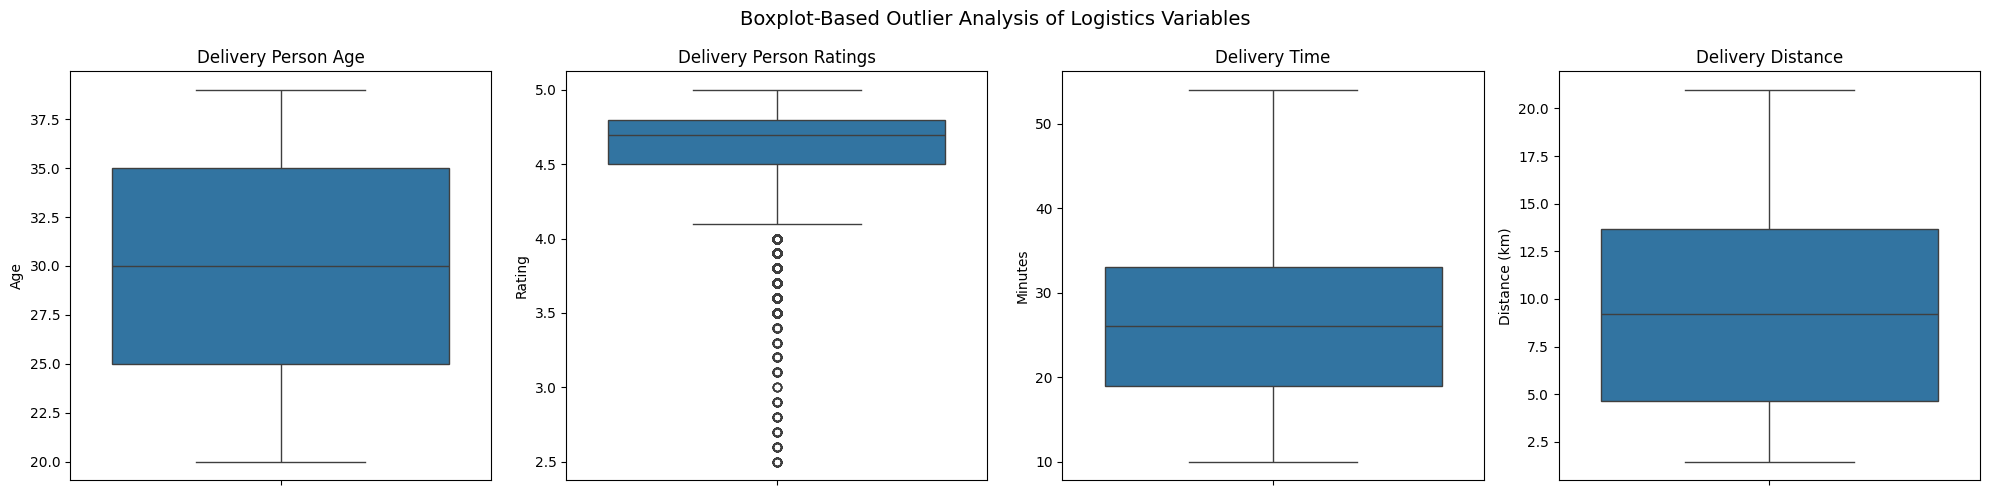

In [63]:
#VISUALIZE OUTLIERS USING BOXPLOTS
# Create a figure with four separate boxplots
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# ------------------------------------------------------------
# Boxplot 1 — Delivery Person Age
# ------------------------------------------------------------

sns.boxplot(
    y=df["Delivery_person_Age"],
    ax=axes[0]
)

axes[0].set_title("Delivery Person Age")
axes[0].set_ylabel("Age")


# ------------------------------------------------------------
# Boxplot 2 — Delivery Person Ratings
# ------------------------------------------------------------

sns.boxplot(
    y=df["Delivery_person_Ratings"],
    ax=axes[1]
)

axes[1].set_title("Delivery Person Ratings")
axes[1].set_ylabel("Rating")


# ------------------------------------------------------------
# Boxplot 3 — Delivery Time
# ------------------------------------------------------------

sns.boxplot(
    y=df["Time_taken (min)"],
    ax=axes[2]
)

axes[2].set_title("Delivery Time")
axes[2].set_ylabel("Minutes")


# ------------------------------------------------------------
# Boxplot 4 — Delivery Distance
# ------------------------------------------------------------

sns.boxplot(
    y=df["distance_km"],
    ax=axes[3]
)

axes[3].set_title("Delivery Distance")
axes[3].set_ylabel("Distance (km)")


# ------------------------------------------------------------
# Final formatting
# ------------------------------------------------------------

plt.suptitle(
    "Boxplot-Based Outlier Analysis of Logistics Variables",
    fontsize=14
)

plt.tight_layout()

plt.show()

In [64]:
# CHECK CATEGORICAL DATA CONSISTENCY
# List the main categorical columns
categorical_columns = [
    "Weather_conditions",
    "Road_traffic_density",
    "Festival",
    "City",
    "Vehicle_condition",
    "delivery_speed"
]

# Display unique values for each categorical variable
for column in categorical_columns:

    print("\n" + "=" * 60)
    print(f"Categorical variable: {column}")
    print("=" * 60)

    print("Unique values:")

    display(
        df[column].value_counts(dropna=False)
    )


Categorical variable: Weather_conditions
Unique values:


,count
Weather_conditions,
Fog,6660
Stormy,6572
Cloudy,6563
Sandstorms,6489
Windy,6436
Sunny,6244



Categorical variable: Road_traffic_density
Unique values:


,count
Road_traffic_density,
Low,13139
Jam,12414
Medium,9556
High,3855



Categorical variable: Festival
Unique values:


...

,count
City,
Metropolitian,30036
Urban,8782
Semi-Urban,146



Categorical variable: Vehicle_condition
Unique values:


,count
Vehicle_condition,
0,13101
1,12936
2,12927



Categorical variable: delivery_speed
Unique values:


,count
delivery_speed,
Average,19982
Fast,10164
Slow,8818


In [65]:
# FINAL DATA QUALITY CHECK
# Count missing values in the current cleaned dataset
final_missing_count = df.isnull().sum().sum()

# Count duplicate rows
final_duplicate_count = df.duplicated().sum()

# Count total rows and columns
final_rows = df.shape[0]
final_columns = df.shape[1]

print("Final Data Quality Check")
print("=" * 50)

print("Total rows:", final_rows)
print("Total columns:", final_columns)
print("Total remaining missing values:", final_missing_count)
print("Total duplicate rows:", final_duplicate_count)

print("\nColumns with remaining missing values:")

remaining_missing = df.isnull().sum()

display(
    remaining_missing[remaining_missing > 0]
)

Final Data Quality Check
Total rows: 38964
Total columns: 23
Total remaining missing values: 1670
Total duplicate rows: 0

Columns with remaining missing values:


,0
Time_Orderd,835
order_hour,835


In [66]:
# SELECT NUMERICAL VARIABLES FOR STANDARDIZATION
# Numerical predictor variables selected for standardization
scaling_columns = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "distance_km"
]

print("Variables selected for standardization:")

for column in scaling_columns:
    print("-", column)

Variables selected for standardization:
- Delivery_person_Age
- Delivery_person_Ratings
- distance_km


In [67]:
# APPLY STANDARDIZATION USING STANDARDSCALER
from sklearn.preprocessing import StandardScaler

# Create the StandardScaler object
scaler = StandardScaler()

# Create scaled versions of the selected variables
scaled_values = scaler.fit_transform(
    df[scaling_columns]
)

# Add the standardized variables as new columns
for i, column in enumerate(scaling_columns):
    df[column + "_scaled"] = scaled_values[:, i]


# ------------------------------------------------------------
# Display original and scaled values
# ------------------------------------------------------------

print("Standardization completed successfully!")

print("\nOriginal and standardized values:")

display(
    df[
        scaling_columns +
        [column + "_scaled" for column in scaling_columns]
    ].head(10)
)

Standardization completed successfully!

Original and standardized values:


,Delivery_person_Age,Delivery_person_Ratings,distance_km,Delivery_person_Age_scaled,Delivery_person_Ratings_scaled,distance_km_scaled
0,36.0,4.2,10.280582,1.122199,-1.386246,0.091959
1,21.0,4.7,6.242319,-1.515111,0.211830,-0.628435
2,23.0,4.7,13.787860,-1.163470,0.211830,0.717630
3,34.0,4.3,2.930258,0.770558,-1.066631,-1.219280
4,24.0,4.7,19.396618,-0.987649,0.211830,1.718187
5,29.0,4.5,13.763977,-0.108545,-0.427400,0.713369
6,35.0,4.0,6.218001,0.946379,-2.025476,-0.632773
7,33.0,4.2,16.849940,0.594737,-1.386246,1.263880
8,21.0,4.7,4.540574,-1.515111,0.211830,-0.932012
9,25.0,4.1,12.256076,-0.811828,-1.705861,0.444372


In [68]:
# VERIFY STANDARDIZATION
print("Mean and standard deviation after standardization:\n")

for column in scaling_columns:
    scaled_column = column + "_scaled"

    print(f"{scaled_column}")
    print(f"Mean: {df[scaled_column].mean():.4f}")
    print(f"Standard deviation: {df[scaled_column].std():.4f}")
    print("-" * 50)

Mean and standard deviation after standardization:

Delivery_person_Age_scaled
Mean: -0.0000
Standard deviation: 1.0000
--------------------------------------------------
Delivery_person_Ratings_scaled
Mean: 0.0000
Standard deviation: 1.0000
--------------------------------------------------
distance_km_scaled
Mean: 0.0000
Standard deviation: 1.0000
--------------------------------------------------


In [69]:
# CREATE PEAK-HOUR FEATURE
# Define peak delivery-order hours
# 12 PM–2 PM and 7 PM–9 PM
peak_hours = [12, 13, 14, 19, 20, 21]

# Create binary peak-hour feature
# Missing order_hour values will remain missing
df["is_peak_hour"] = np.where(
    df["order_hour"].isna(),
    np.nan,
    df["order_hour"].isin(peak_hours).astype(int)
)

print("Peak-hour feature created successfully!")

print("\nPeak-hour distribution:")
print(df["is_peak_hour"].value_counts(dropna=False))

Peak-hour feature created successfully!

Peak-hour distribution:
is_peak_hour
0.0    23778
1.0    14351
NaN      835
Name: count, dtype: int64


In [70]:
# VERIFY PEAK-HOUR FEATURE
print("Unique values in is_peak_hour:")
print(df["is_peak_hour"].unique())

print("\nPeak-hour feature data types:")
print(df["is_peak_hour"].dtype)

print("\nSample of order hour and peak-hour classification:")

display(
    df[
        ["order_hour", "is_peak_hour"]
    ].head(15)
)

Unique values in is_peak_hour:
[ 1.  0. nan]

Peak-hour feature data types:
float64

Sample of order hour and peak-hour classification:


,order_hour,is_peak_hour
0,21.0,1.0
1,14.0,1.0
2,17.0,0.0
3,9.0,0.0
4,19.0,1.0
5,20.0,1.0
6,14.0,1.0
7,20.0,1.0
8,21.0,1.0
9,20.0,1.0


In [71]:
# BEFORE VS AFTER DATA QUALITY COMPARISON
# Original dataset statistics
original_rows = df_original.shape[0]
original_columns = df_original.shape[1]
original_missing = df_original.isnull().sum().sum()
original_duplicates = df_original.duplicated().sum()

# Processed dataset statistics
processed_rows = df.shape[0]
processed_columns = df.shape[1]
processed_missing = df.isnull().sum().sum()
processed_duplicates = df.duplicated().sum()

# Create comparison table
quality_comparison = pd.DataFrame({
    "Metric": [
        "Rows",
        "Columns",
        "Total Missing Values",
        "Duplicate Rows"
    ],
    "Before Preprocessing": [
        original_rows,
        original_columns,
        original_missing,
        original_duplicates
    ],
    "After Preprocessing": [
        processed_rows,
        processed_columns,
        processed_missing,
        processed_duplicates
    ]
})

print("BEFORE VS AFTER DATA QUALITY COMPARISON")
display(quality_comparison)

BEFORE VS AFTER DATA QUALITY COMPARISON


,Metric,Before Preprocessing,After Preprocessing
0,Rows,38964,38964
1,Columns,22,27
2,Total Missing Values,2909,2505
3,Duplicate Rows,0,0


In [72]:
# FINAL MISSING VALUE BREAKDOWN
remaining_missing = df.isnull().sum()

remaining_missing = remaining_missing[
    remaining_missing > 0
].sort_values(ascending=False)

print("REMAINING MISSING VALUES BY COLUMN:\n")

display(
    remaining_missing.to_frame(
        name="Missing Values"
    )
)

REMAINING MISSING VALUES BY COLUMN:



,Missing Values
Time_Orderd,835
order_hour,835
is_peak_hour,835


In [73]:
# CREATE FINAL PREPROCESSED DATASET
# Create a final copy of the processed dataset
df_processed = df.copy()

# Reset the index after all preprocessing operations
df_processed.reset_index(drop=True, inplace=True)

print("Final preprocessed dataset created successfully!")

print("\nDataset shape:")
print(df_processed.shape)

print("\nFinal duplicate count:")
print(df_processed.duplicated().sum())

print("\nFinal missing values:")
print(df_processed.isnull().sum().sum())

Final preprocessed dataset created successfully!

Dataset shape:
(38964, 27)

Final duplicate count:
0

Final missing values:
2505


In [74]:
# FINAL PREPROCESSING VALIDATION
print("=" * 60)
print("FINAL PREPROCESSING VALIDATION")
print("=" * 60)

# 1. Dataset dimensions
print("\n1. Dataset Dimensions")
print("Rows:", df_processed.shape[0])
print("Columns:", df_processed.shape[1])

# 2. Duplicate check
print("\n2. Duplicate Check")
print("Duplicate rows:", df_processed.duplicated().sum())

# 3. Missing-value check
print("\n3. Missing-Value Check")
print("Total missing cells:", df_processed.isnull().sum().sum())

# 4. Standardized-variable check
print("\n4. Standardized Variables")

for column in scaling_columns:
    scaled_column = column + "_scaled"

    print(
        f"{scaled_column}: "
        f"Mean = {df_processed[scaled_column].mean():.4f}, "
        f"Std = {df_processed[scaled_column].std():.4f}"
    )

# 5. Peak-hour validation
print("\n5. Peak-Hour Feature")
print(
    df_processed["is_peak_hour"]
    .value_counts(dropna=False)
)

# 6. Final data types
print("\n6. Data Types")
print(df_processed.dtypes)

FINAL PREPROCESSING VALIDATION

1. Dataset Dimensions
Rows: 38964
Columns: 27

2. Duplicate Check
Duplicate rows: 0

3. Missing-Value Check
Total missing cells: 2505

4. Standardized Variables
Delivery_person_Age_scaled: Mean = -0.0000, Std = 1.0000
Delivery_person_Ratings_scaled: Mean = 0.0000, Std = 1.0000
distance_km_scaled: Mean = 0.0000, Std = 1.0000

5. Peak-Hour Feature
is_peak_hour
0.0    23778
1.0    14351
NaN      835
Name: count, dtype: int64

6. Data Types
ID                                        object
Delivery_person_ID                        object
Delivery_person_Age                      float64
Delivery_person_Ratings                  float64
Restaurant_latitude                      float64
Restaurant_longitude                     float64
Delivery_location_latitude               float64
Delivery_location_longitude              float64
Order_Date                                object
Time_Orderd                       datetime64[ns]
Time_Order_picked                    

In [75]:
# EXPORT FINAL PREPROCESSED DATASET
output_file = "/content/Week_2_Preprocessed_Logistics_Dataset.csv"

# Save the final processed dataset
df_processed.to_csv(
    output_file,
    index=False
)

print("Final preprocessed dataset exported successfully!")
print("\nFile location:")
print(output_file)

Final preprocessed dataset exported successfully!

File location:
/content/Week_2_Preprocessed_Logistics_Dataset.csv


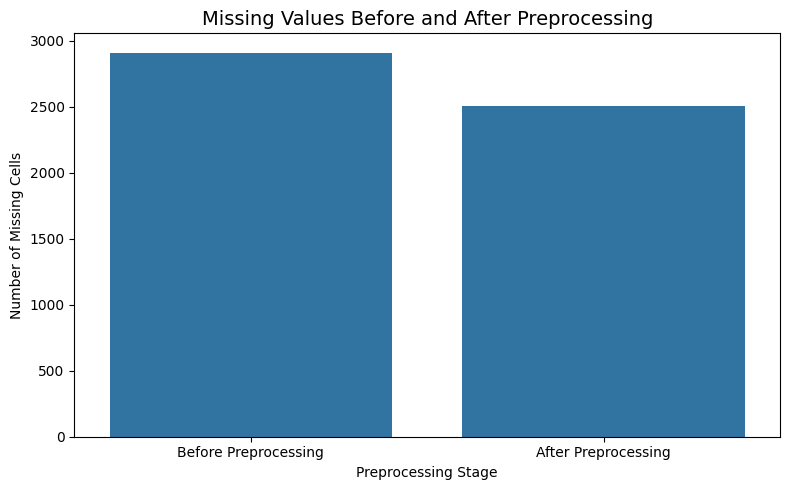

In [76]:
# PLOT MISSING VALUES BEFORE VS AFTER
# Data for the comparison
missing_comparison = pd.DataFrame({
    "Stage": [
        "Before Preprocessing",
        "After Preprocessing"
    ],
    "Missing Values": [
        original_missing,
        processed_missing
    ]
})

# Create the figure
plt.figure(figsize=(8, 5))

sns.barplot(
    data=missing_comparison,
    x="Stage",
    y="Missing Values"
)

plt.title(
    "Missing Values Before and After Preprocessing",
    fontsize=14
)

plt.xlabel("Preprocessing Stage")
plt.ylabel("Number of Missing Cells")

plt.tight_layout()
plt.show()

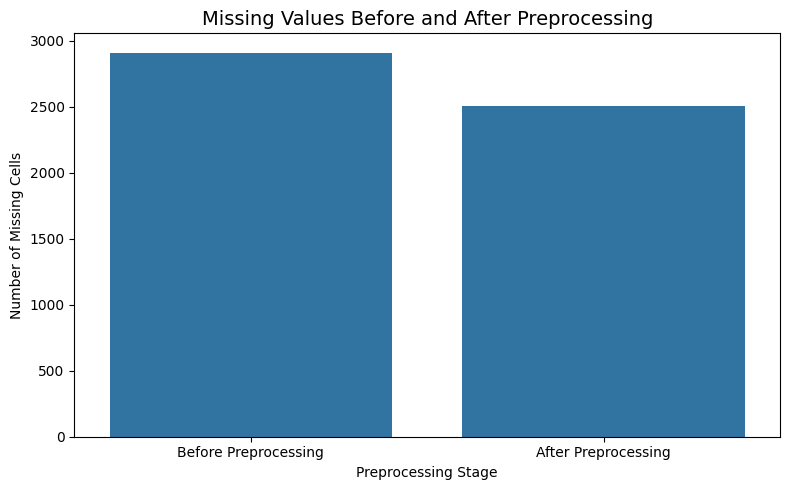

Figure 1 saved successfully!
/content/missing_values_before_after.png


In [77]:
# SAVE MISSING-VALUE FIGURE
figure1_path = "/content/missing_values_before_after.png"

plt.figure(figsize=(8, 5))

sns.barplot(
    data=missing_comparison,
    x="Stage",
    y="Missing Values"
)

plt.title(
    "Missing Values Before and After Preprocessing",
    fontsize=14
)

plt.xlabel("Preprocessing Stage")
plt.ylabel("Number of Missing Cells")

plt.tight_layout()

plt.savefig(
    figure1_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 1 saved successfully!")
print(figure1_path)

In [78]:
# CREATE OUTLIER SUMMARY FOR VISUALIZATION
# Calculate IQR-based outlier counts
outlier_summary = []

for column in outlier_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ).sum()

    outlier_summary.append({
        "Variable": column,
        "IQR Outliers": outlier_count
    })

outlier_summary_df = pd.DataFrame(outlier_summary)

print("IQR OUTLIER SUMMARY")
display(outlier_summary_df)

IQR OUTLIER SUMMARY


,Variable,IQR Outliers
0,Delivery_person_Age,0
1,Delivery_person_Ratings,2147
2,Time_taken (min),0
3,distance_km,0


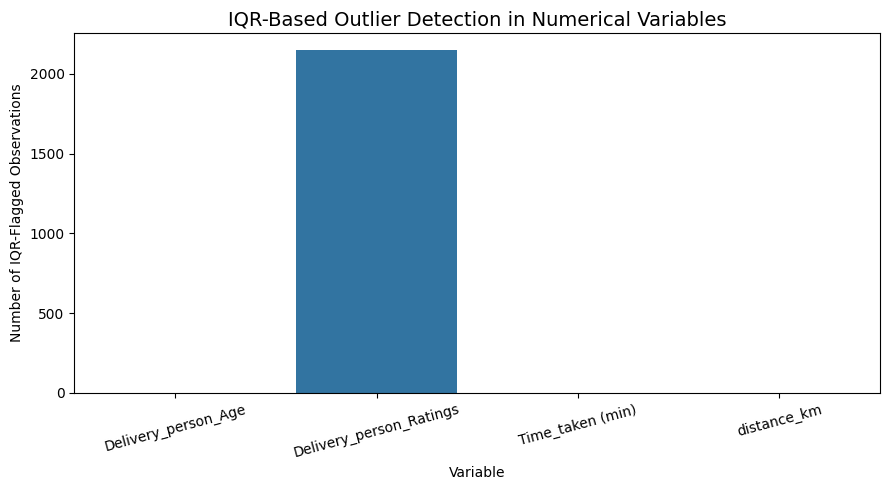

Figure 2 saved successfully!
/content/outlier_analysis.png


In [79]:
# CREATE AND SAVE OUTLIER ANALYSIS FIGURE
plt.figure(figsize=(9, 5))

sns.barplot(
    data=outlier_summary_df,
    x="Variable",
    y="IQR Outliers"
)

plt.title(
    "IQR-Based Outlier Detection in Numerical Variables",
    fontsize=14
)

plt.xlabel("Variable")
plt.ylabel("Number of IQR-Flagged Observations")

plt.xticks(rotation=15)

plt.tight_layout()

# Save the figure
figure2_path = "/content/outlier_analysis.png"

plt.savefig(
    figure2_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 2 saved successfully!")
print(figure2_path)

In [80]:
# OUTLIER ANALYSIS INTERPRETATION
print("OUTLIER ANALYSIS — KEY FINDINGS")
print("-" * 50)

print("Delivery_person_Age:")
print("No IQR-based outliers were detected.")

print("\nDelivery_person_Ratings:")
print("2,147 observations were flagged by the IQR method.")
print("These values were checked against the valid rating range of 1–5.")
print("No ratings were outside the valid domain.")

print("\nTime_taken (min):")
print("No IQR-based outliers were detected.")

print("\ndistance_km:")
print("No IQR-based outliers were detected.")

print("\nDecision:")
print("No observations were removed solely because of IQR-based outlier detection.")

OUTLIER ANALYSIS — KEY FINDINGS
--------------------------------------------------
Delivery_person_Age:
No IQR-based outliers were detected.

Delivery_person_Ratings:
2,147 observations were flagged by the IQR method.
These values were checked against the valid rating range of 1–5.
No ratings were outside the valid domain.

Time_taken (min):
No IQR-based outliers were detected.

distance_km:
No IQR-based outliers were detected.

Decision:
No observations were removed solely because of IQR-based outlier detection.


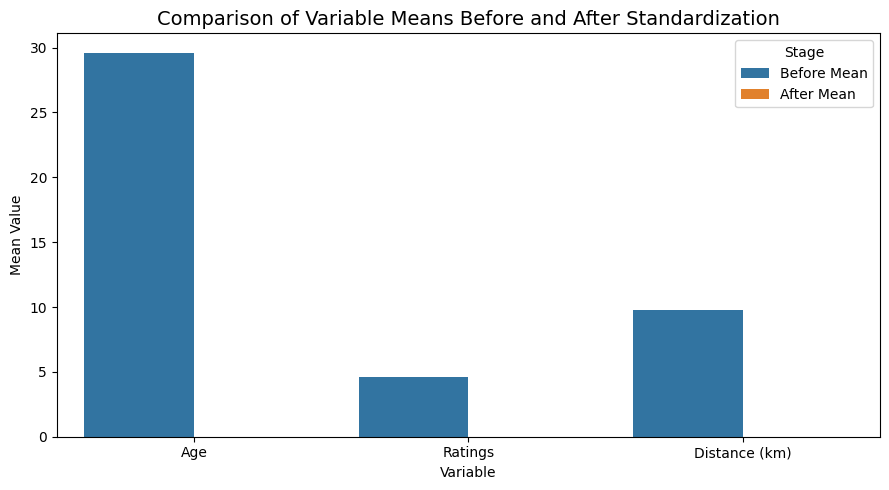

Figure 3 saved successfully!
/content/scaling_comparison.png


In [81]:
# CREATE AND SAVE STANDARDIZATION COMPARISON FIGURE
# Select variables for comparison
comparison_data = pd.DataFrame({
    "Variable": [
        "Age",
        "Ratings",
        "Distance (km)"
    ],
    "Before Mean": [
        df["Delivery_person_Age"].mean(),
        df["Delivery_person_Ratings"].mean(),
        df["distance_km"].mean()
    ],
    "After Mean": [
        df["Delivery_person_Age_scaled"].mean(),
        df["Delivery_person_Ratings_scaled"].mean(),
        df["distance_km_scaled"].mean()
    ]
})

# Reshape data for plotting
plot_data = comparison_data.melt(
    id_vars="Variable",
    value_vars=["Before Mean", "After Mean"],
    var_name="Stage",
    value_name="Mean"
)

# Create comparison chart
plt.figure(figsize=(9, 5))

sns.barplot(
    data=plot_data,
    x="Variable",
    y="Mean",
    hue="Stage"
)

plt.title(
    "Comparison of Variable Means Before and After Standardization",
    fontsize=14
)

plt.xlabel("Variable")
plt.ylabel("Mean Value")

plt.tight_layout()

# Save the figure
figure3_path = "/content/scaling_comparison.png"

plt.savefig(
    figure3_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 3 saved successfully!")
print(figure3_path)

In [82]:
# VALIDATE STANDARDIZED VARIABLES
# Create validation table
scaling_validation = pd.DataFrame({
    "Variable": [
        "Delivery_person_Age_scaled",
        "Delivery_person_Ratings_scaled",
        "distance_km_scaled"
    ],
    "Mean": [
        df["Delivery_person_Age_scaled"].mean(),
        df["Delivery_person_Ratings_scaled"].mean(),
        df["distance_km_scaled"].mean()
    ],
    "Standard Deviation": [
        df["Delivery_person_Age_scaled"].std(),
        df["Delivery_person_Ratings_scaled"].std(),
        df["distance_km_scaled"].std()
    ]
})

# Round values for easier reading
scaling_validation["Mean"] = scaling_validation["Mean"].round(4)
scaling_validation["Standard Deviation"] = scaling_validation["Standard Deviation"].round(4)

print("STANDARDIZATION VALIDATION")
print("-" * 60)

display(scaling_validation)

print("\nInterpretation:")
print("The standardized variables have means approximately equal to 0")
print("and standard deviations approximately equal to 1.")

STANDARDIZATION VALIDATION
------------------------------------------------------------


,Variable,Mean,Standard Deviation
0,Delivery_person_Age_scaled,-0.0,1.0
1,Delivery_person_Ratings_scaled,0.0,1.0
2,distance_km_scaled,0.0,1.0



Interpretation:
The standardized variables have means approximately equal to 0
and standard deviations approximately equal to 1.


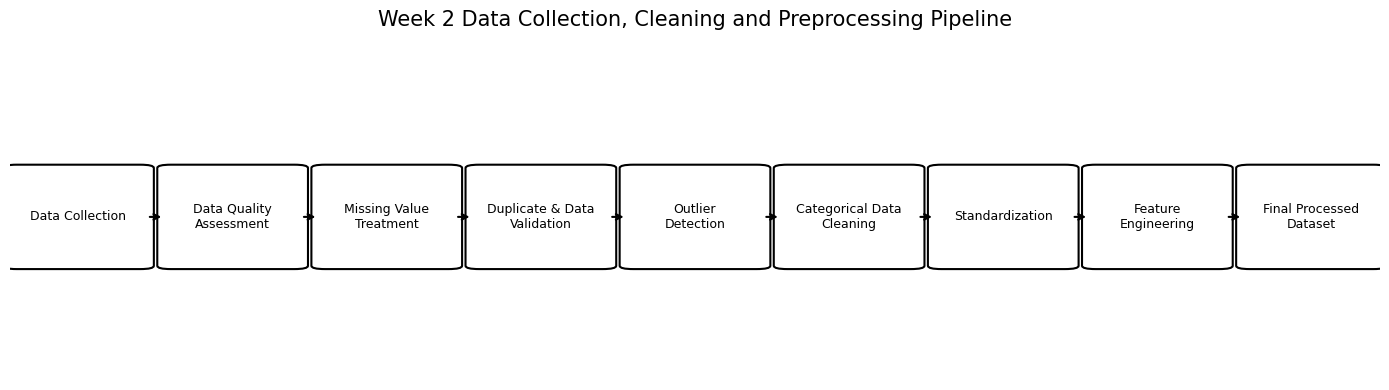

Figure 4 saved successfully!
/content/preprocessing_pipeline.png


In [83]:
# CREATE AND SAVE PREPROCESSING PIPELINE DIAGRAM
from matplotlib.patches import FancyBboxPatch

# Create figure
fig, ax = plt.subplots(figsize=(14, 4))

# Hide axes
ax.axis("off")

# Pipeline stages
steps = [
    "Data Collection",
    "Data Quality\nAssessment",
    "Missing Value\nTreatment",
    "Duplicate & Data\nValidation",
    "Outlier\nDetection",
    "Categorical Data\nCleaning",
    "Standardization",
    "Feature\nEngineering",
    "Final Processed\nDataset"
]

# Positions
x_positions = np.linspace(0.05, 0.95, len(steps))

# Draw boxes
for i, (x, step) in enumerate(zip(x_positions, steps)):

    box = FancyBboxPatch(
        (x - 0.045, 0.35),
        0.09,
        0.30,
        boxstyle="round,pad=0.01",
        linewidth=1.5,
        facecolor="white",
        edgecolor="black"
    )

    ax.add_patch(box)

    ax.text(
        x,
        0.50,
        step,
        ha="center",
        va="center",
        fontsize=9
    )

    # Add arrows between stages
    if i < len(steps) - 1:
        ax.annotate(
            "",
            xy=(x_positions[i + 1] - 0.05, 0.50),
            xytext=(x + 0.05, 0.50),
            arrowprops=dict(
                arrowstyle="->",
                linewidth=1.5
            )
        )

# Title
plt.title(
    "Week 2 Data Collection, Cleaning and Preprocessing Pipeline",
    fontsize=15,
    pad=20
)

plt.tight_layout()

# Save figure
figure4_path = "/content/preprocessing_pipeline.png"

plt.savefig(
    figure4_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 4 saved successfully!")
print(figure4_path)

In [84]:
# VERIFY EXPORTED PREPROCESSED DATASET
# Load the exported dataset
df_check = pd.read_csv("/content/Week_2_Preprocessed_Logistics_Dataset.csv")

# Display basic verification information
print("FINAL DATASET EXPORT VERIFICATION")
print("-" * 60)

print("Original processed dataframe shape:", df_processed.shape)
print("Exported CSV shape:", df_check.shape)

print("\nOriginal processed rows:", len(df_processed))
print("Exported CSV rows:", len(df_check))

print("\nOriginal processed columns:", len(df_processed.columns))
print("Exported CSV columns:", len(df_check.columns))

print("\nMissing values in exported dataset:", df_check.isna().sum().sum())
print("Duplicate rows in exported dataset:", df_check.duplicated().sum())

# Final verification
if df_processed.shape == df_check.shape:
    print("\n✓ Shape verification: PASSED")
else:
    print("\n✗ Shape verification: FAILED")

if df_check.duplicated().sum() == 0:
    print("✓ Duplicate verification: PASSED")
else:
    print("✗ Duplicate verification: FAILED")

print("\nExport verification completed.")

FINAL DATASET EXPORT VERIFICATION
------------------------------------------------------------
Original processed dataframe shape: (38964, 27)
Exported CSV shape: (38964, 27)

Original processed rows: 38964
Exported CSV rows: 38964

Original processed columns: 27
Exported CSV columns: 27

Missing values in exported dataset: 2505
Duplicate rows in exported dataset: 0

✓ Shape verification: PASSED
✓ Duplicate verification: PASSED

Export verification completed.


In [85]:
# FINAL DATA QUALITY REPORT
print("=" * 70)
print("FINAL DATA QUALITY REPORT — WEEK 2")
print("=" * 70)

# ------------------------------------------------------------
# 1. Dataset Dimensions
# ------------------------------------------------------------

print("\n1. DATASET DIMENSIONS")
print("-" * 50)

print("Rows:", df_processed.shape[0])
print("Columns:", df_processed.shape[1])


# ------------------------------------------------------------
# 2. Missing Value Summary
# ------------------------------------------------------------

print("\n2. MISSING VALUE SUMMARY")
print("-" * 50)

print("Missing values before preprocessing:", original_missing)
print("Missing values after preprocessing:", processed_missing)
print("Missing values reduced:", original_missing - processed_missing)

print("\nRemaining missing values by column:")

remaining_missing = df_processed.isna().sum()

remaining_missing = remaining_missing[
    remaining_missing > 0
]

print(remaining_missing)


# ------------------------------------------------------------
# 3. Duplicate Check
# ------------------------------------------------------------

print("\n3. DUPLICATE CHECK")
print("-" * 50)

print("Duplicate rows:", df_processed.duplicated().sum())


# ------------------------------------------------------------
# 4. Rating Validation
# ------------------------------------------------------------

print("\n4. RATING VALIDATION")
print("-" * 50)

valid_ratings = df_processed[
    df_processed["Delivery_person_Ratings"].between(1, 5)
]

invalid_rating_count = len(df_processed) - len(valid_ratings)

print("Invalid ratings outside 1–5:", invalid_rating_count)


# ------------------------------------------------------------
# 5. Standardization Validation
# ------------------------------------------------------------

print("\n5. STANDARDIZATION VALIDATION")
print("-" * 50)

for column in scaling_columns:
    mean_value = df_processed[column + "_scaled"].mean()
    std_value = df_processed[column + "_scaled"].std()

    print(
        f"{column}: "
        f"Mean = {mean_value:.4f}, "
        f"Std = {std_value:.4f}"
    )


# ------------------------------------------------------------
# 6. Feature Engineering Validation
# ------------------------------------------------------------

print("\n6. FEATURE ENGINEERING VALIDATION")
print("-" * 50)

print("order_hour missing values:",
      df_processed["order_hour"].isna().sum())

print("\nis_peak_hour distribution:")
print(df_processed["is_peak_hour"].value_counts(dropna=False))


# ------------------------------------------------------------
# 7. Exported Dataset Verification
# ------------------------------------------------------------

print("\n7. EXPORTED DATASET")
print("-" * 50)

print("Exported file:",
      "/content/Week_2_Preprocessed_Logistics_Dataset.csv")

print("Exported shape:",
      df_check.shape)

print("Exported duplicate rows:",
      df_check.duplicated().sum())


# ------------------------------------------------------------
# 8. Final Status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL STATUS")
print("=" * 70)

print("✓ Dataset dimensions verified")
print("✓ Missing-value processing completed")
print("✓ Duplicate check completed")
print("✓ Domain validation completed")
print("✓ Outlier analysis completed")
print("✓ Standardization verified")
print("✓ Feature engineering verified")
print("✓ CSV export verified")

print("\nWEEK 2 PREPROCESSING PIPELINE COMPLETED SUCCESSFULLY!")
print("=" * 70)


FINAL DATA QUALITY REPORT — WEEK 2

1. DATASET DIMENSIONS
--------------------------------------------------
Rows: 38964
Columns: 27

2. MISSING VALUE SUMMARY
--------------------------------------------------
Missing values before preprocessing: 2909
Missing values after preprocessing: 2505
Missing values reduced: 404

Remaining missing values by column:
Time_Orderd     835
order_hour      835
is_peak_hour    835
dtype: int64

3. DUPLICATE CHECK
--------------------------------------------------
Duplicate rows: 0

4. RATING VALIDATION
--------------------------------------------------
Invalid ratings outside 1–5: 0

5. STANDARDIZATION VALIDATION
--------------------------------------------------
Delivery_person_Age: Mean = -0.0000, Std = 1.0000
Delivery_person_Ratings: Mean = 0.0000, Std = 1.0000
distance_km: Mean = 0.0000, Std = 1.0000

6. FEATURE ENGINEERING VALIDATION
--------------------------------------------------
order_hour missing values: 835

is_peak_hour distribution:
is_pe